# 5. Data Visualization using matplotlib
Problem Statement: Analyzing Air Quality Index (AQI) Trends in a City<br>
Dataset: "City_Air_Quality.csv"<br>
Description: The dataset contains information about air quality measurements in a specific
city over a period of time. It includes attributes such as date, time, pollutant levels (e.g., PM2.5,
PM10, CO), and the Air Quality Index (AQI) values. The goal is to use the matplotlib library
to create visualizations that effectively represent the AQI trends and patterns for different
pollutants in the city.<br>
Tasks to Perform:<br>
1. Import the "City_Air_Quality.csv" dataset.<br>
2. Explore the dataset to understand its structure and content.<br>
3. Identify the relevant variables for visualizing AQI trends, such as date, pollutant levels,
and AQI values.<br>
4. Create line plots or time series plots to visualize the overall AQI trend over time.<br>
5. Plot individual pollutant levels (e.g., PM2.5, PM10, CO) on separate line plots to
visualize their trends over time.<br>
6. Use bar plots or stacked bar plots to compare the AQI values across different dates or
time periods.<br>
7. Create box plots or violin plots to analyze the distribution of AQI values for different
pollutant categories.<br>
8. Use scatter plots or bubble charts to explore the relationship between AQI values and
pollutant levels.<br>
9. Customize the visualizations by adding labels, titles, legends, and appropriate color
schemes.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [3]:

# Load dataset
df = pd.read_csv("AirQuality.csv")

# Explore dataset
print(df.head())
print(df.info())
print(df.describe())


        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City

In [4]:
# Clean data
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

pollutants = ["PM2.5", "PM10", "CO"]

for col in pollutants + ["AQI"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Date", "AQI"])
df = df.sort_values("Date")

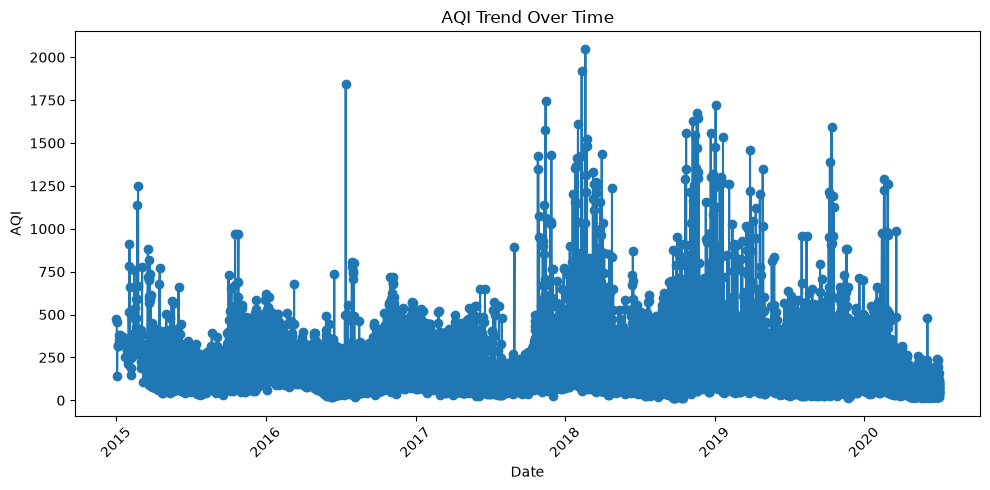

In [5]:
# 1. AQI trend
plt.figure(figsize=(10, 5))
plt.plot(df["Date"], df["AQI"], marker="o")
plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

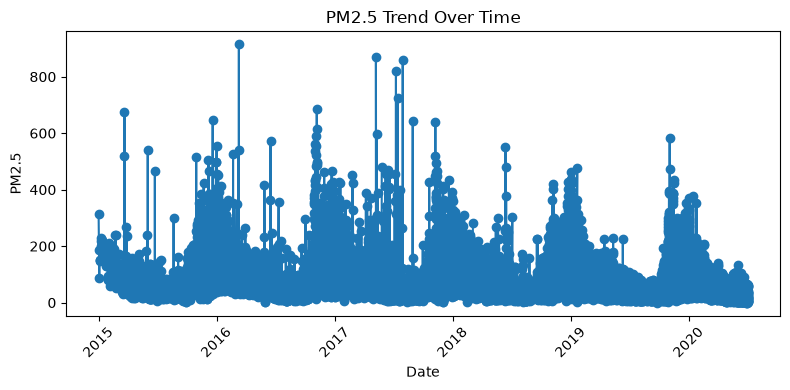

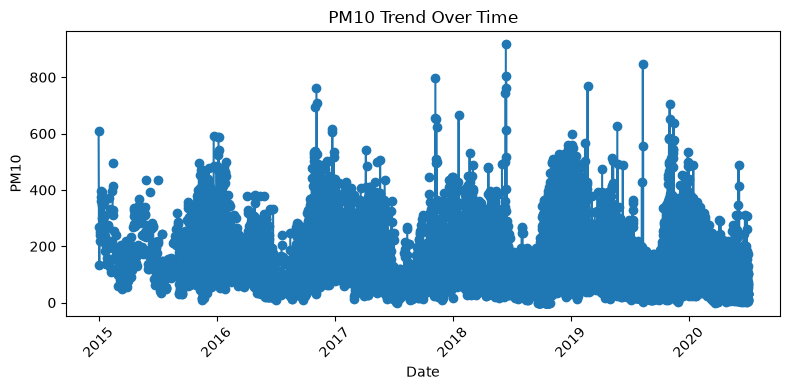

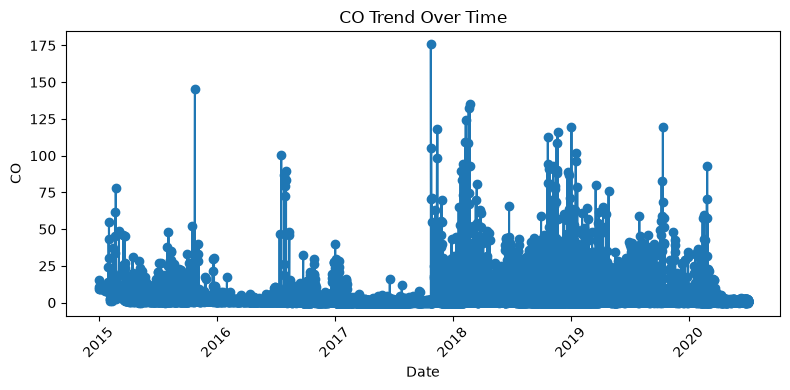

In [6]:
# 2. Individual pollutant trends
for col in pollutants:
    plt.figure(figsize=(8, 4))
    plt.plot(df["Date"], df[col], marker="o")
    plt.title(col + " Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

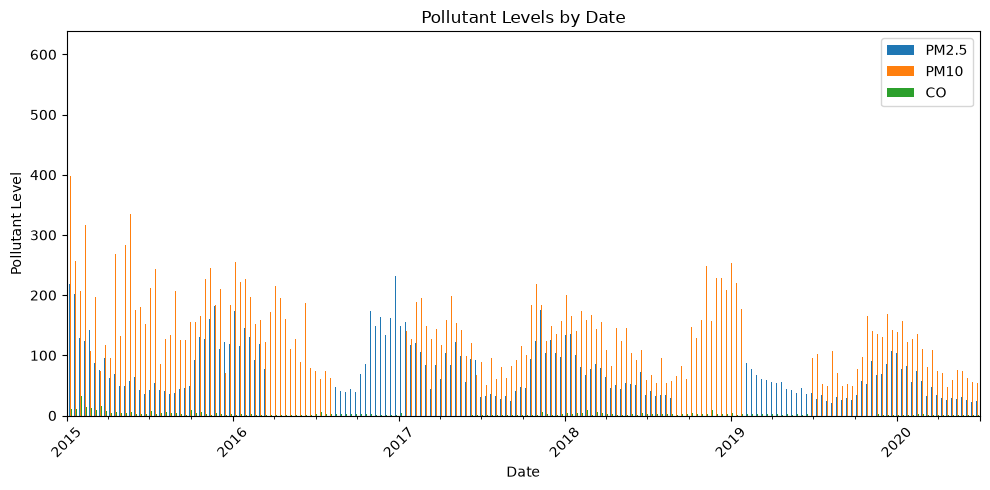

In [7]:

# 3. Bar chart of pollutant levels
daily = df.groupby("Date")[pollutants].mean()

daily.plot(kind="bar", figsize=(10, 5))
plt.title("Pollutant Levels by Date")
plt.xlabel("Date")
plt.ylabel("Pollutant Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


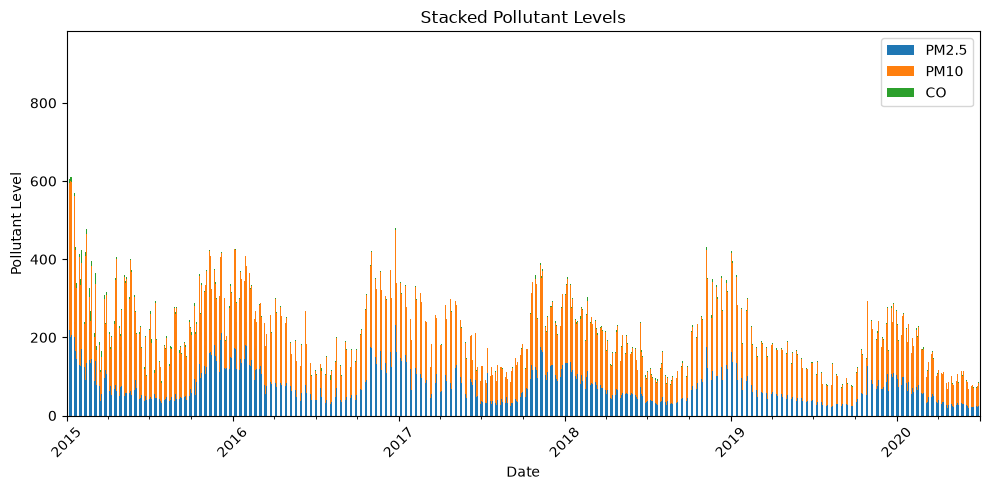

In [8]:
# 4. Stacked bar chart
daily.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Stacked Pollutant Levels")
plt.xlabel("Date")
plt.ylabel("Pollutant Level")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

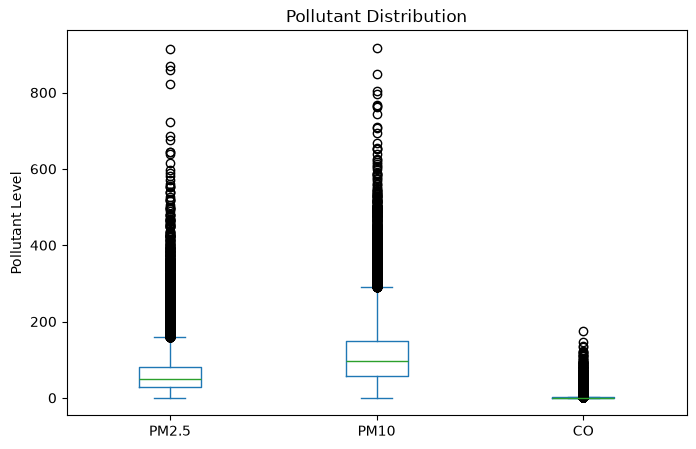

In [9]:
# 5. Box plot
df[pollutants].plot(kind="box", figsize=(8, 5))
plt.title("Pollutant Distribution")
plt.ylabel("Pollutant Level")
plt.show()

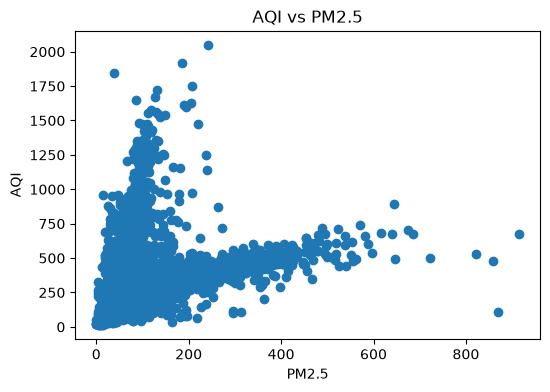

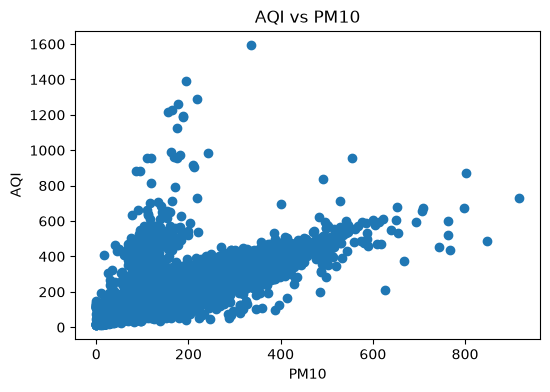

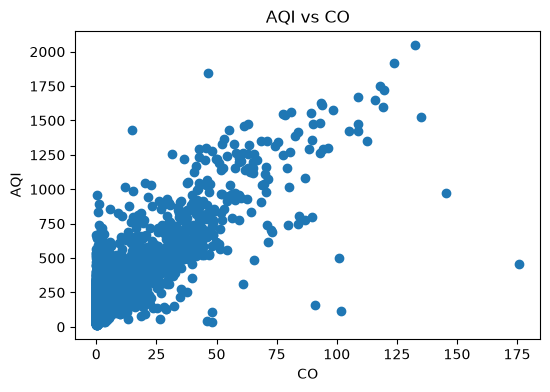

In [10]:
# 6. Scatter plots: AQI vs pollutants
for col in pollutants:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["AQI"])
    plt.title("AQI vs " + col)
    plt.xlabel(col)
    plt.ylabel("AQI")
    plt.show()